# MSc Project: Cross-Planetary Domain Adaptation: Transfer Learning for Lunar to Martian Crater Detection under Low-Data Regimes

## 1. Environment Setup & Data Engineering

---




In [1]:
from google.colab import drive
drive.mount('/content/drive')

%pip install ultralytics

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 6.5 MB/s eta 0:00:00


In [2]:
import ultralytics
import os
import shutil
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import cv2
from scipy import stats
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
# Setup google drive project path
project_dir = '/content/drive/MyDrive/MSc Project'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir) # move into the folder

# Add kaggle token so we can download datasets directly
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_540676efa98ce2002f28dda0dd7a27a5'

In [4]:
# Download Lunar Dataset to local Colab memory
!kaggle datasets download -d riccardolagrassa/lu3m6tgt -p /content/datasets/lunar --unzip

# Download Martian/Lunar Dataset to local Colab memory
!kaggle datasets download -d lincolnzh/martianlunar-crater-detection-dataset -p /content/datasets/martian --unzip

Dataset URL: https://www.kaggle.com/datasets/riccardolagrassa/lu3m6tgt
License(s): CC-BY-SA-4.0
100% 1.11G/1.11G [00:30<00:00, 38.6MB/s]

Dataset URL: https://www.kaggle.com/datasets/lincolnzh/martianlunar-crater-detection-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 74.0M/74.0M [00:02<00:00, 31.5MB/s]



Filtering mixed dataset to only include martian images...

In [5]:
# The martian dataset has moon images mixed in, so we need to filter them out
base_path = '/content/datasets/martian/craters'
splits = ['train', 'valid', 'test']

# Setup directory for pure martian images
clean_dir = '/content/datasets/pure_martian'
images_out = os.path.join(clean_dir, 'images')
labels_out = os.path.join(clean_dir, 'labels')
folds_dir = os.path.join(clean_dir, 'folds')

# Create the new directories
os.makedirs(images_out, exist_ok=True)
os.makedirs(labels_out, exist_ok=True)
os.makedirs(folds_dir, exist_ok=True)

# Loop through splits to extract only martian images
total_moved = 0
for split in splits:
    img_dir = os.path.join(base_path, split, 'images')
    lbl_dir = os.path.join(base_path, split, 'labels')

    if not os.path.exists(img_dir):
        continue

    for img_file in os.listdir(img_dir):
        # Filter to drop all lunar images
        if 'mars' in img_file.lower():
            # Copy the image
            shutil.copy(os.path.join(img_dir, img_file), os.path.join(images_out, img_file))

            # Copy the matching label file
            lbl_file = os.path.splitext(img_file)[0] + '.txt'
            if os.path.exists(os.path.join(lbl_dir, lbl_file)):
                shutil.copy(os.path.join(lbl_dir, lbl_file), os.path.join(labels_out, lbl_file))

            total_moved += 1

print(f"Consolidated {total_moved} pure Martian images.")

Consolidated 119 pure Martian images.


In [6]:
from sklearn.model_selection import KFold

# Get all the filtered martian images
image_paths = [os.path.join(images_out, f) for f in os.listdir(images_out)]

# Split into 5 folds with a random seed for reproducibility
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Generate the 5-fold cross-validation splits
fold_number = 1
for train_idx, val_idx in kf.split(image_paths):
    # Split the data into training and validation sets for this fold
    train_paths = [image_paths[i] for i in train_idx]
    val_paths = [image_paths[i] for i in val_idx]

    # save the paths to text files so YOLO can read them
    train_txt = os.path.join(folds_dir, f'train_fold_{fold_number}.txt')
    with open(train_txt, 'w') as f:
        f.write('\n'.join(train_paths))

    val_txt = os.path.join(folds_dir, f'val_fold_{fold_number}.txt')
    with open(val_txt, 'w') as f:
        f.write('\n'.join(val_paths))

    # Create the YOLO YAML configuration file
    yaml_path = os.path.join(folds_dir, f'fold_{fold_number}.yaml')
    with open(yaml_path, 'w') as f:
        f.write(f"train: {train_txt}\n")
        f.write(f"val: {val_txt}\n")
        f.write("\n")
        f.write("nc: 1\n") # number of classes
        f.write("names: ['crater']\n")

    print(f"Fold {fold_number} created: {len(train_paths)} training images, {len(val_paths)} validation images.")
    fold_number += 1

print("\nAll 5 YAML configurations generated successfully.")

Fold 1 created: 95 training images, 24 validation images.
Fold 2 created: 95 training images, 24 validation images.
Fold 3 created: 95 training images, 24 validation images.
Fold 4 created: 95 training images, 24 validation images.
Fold 5 created: 96 training images, 23 validation images.

All 5 YAML configurations generated successfully.


In [7]:
# clean up original dataset to free up space on colab
shutil.rmtree('/content/datasets/martian')

### Tests

In [8]:
# Test 1: Data Purity
# Sanity check to make sure no moon images sneaked in

images_dir = '/content/datasets/pure_martian/images'
labels_dir = '/content/datasets/pure_martian/labels'

images = os.listdir(images_dir)
labels = os.listdir(labels_dir)

print("Test 1: Data Purity\n")

# Check for non-martian files
moon_contamination = [img for img in images if 'mars' not in img.lower()]
if not moon_contamination:
    print("Passed. 0 non-martian images detected.")
else:
    print(f"Failed. {len(moon_contamination)} non-martian images found.")

# Check for missing label files
missing_labels = 0
for img in images:
    label_name = os.path.splitext(img)[0] + '.txt'
    if not os.path.exists(os.path.join(labels_dir, label_name)):
        missing_labels += 1

if missing_labels == 0:
    print("Passed. All images have matching labels.")
else:
    print(f"Failed. {missing_labels} missing labels.")

Test 1: Data Purity

Passed. 0 non-martian images detected.
Passed. All images have matching labels.


In [9]:
# Test 2: Data Leakage Check
# Double check there is no data leakage between train and val sets

folds_dir = '/content/datasets/pure_martian/folds'

print("Test 2: Data Leakage Check\n")
leakage_found = False

for i in range(1, 6):
    train_txt = os.path.join(folds_dir, f'train_fold_{i}.txt')
    val_txt = os.path.join(folds_dir, f'val_fold_{i}.txt')

    # load train and val lists as sets
    with open(train_txt, 'r') as f:
        train_set = set(f.read().splitlines())

    with open(val_txt, 'r') as f:
        val_set = set(f.read().splitlines())

    # Check intersection for leakage
    overlap = train_set.intersection(val_set)

    if len(overlap) > 0:
        print(f"Fold {i}: Failed. {len(overlap)} overlapping images found.")
        leakage_found = True
    else:
        print(f"Fold {i}: Passed. Train and validation sets are strictly separated.")

if not leakage_found:
    print("Passed. No data leakage detected across any folds.")

Test 2: Data Leakage Check

Fold 1: Passed. Train and validation sets are strictly separated.
Fold 2: Passed. Train and validation sets are strictly separated.
Fold 3: Passed. Train and validation sets are strictly separated.
Fold 4: Passed. Train and validation sets are strictly separated.
Fold 5: Passed. Train and validation sets are strictly separated.
Passed. No data leakage detected across any folds.


In [10]:
# Test 3: YAML Configuration Check

folds_dir = '/content/datasets/pure_martian/folds'

print("Test 3: YAML Configuration Check\n")
for i in range(1, 6):
    yaml_path = os.path.join(folds_dir, f'fold_{i}.yaml')

    if not os.path.exists(yaml_path):
        print(f"Fold {i} YAML: Failed. File not found.")
        continue

    with open(yaml_path, 'r') as f:
        content = f.read()

    # Verify required keys exist
    if 'train:' in content and 'val:' in content and 'nc: 1' in content:
        print(f"Fold {i} YAML: Passed.")
    else:
        print(f"Fold {i} YAML: Failed. Missing parameters.")

Test 3: YAML Configuration Check

Fold 1 YAML: Passed.
Fold 2 YAML: Passed.
Fold 3 YAML: Passed.
Fold 4 YAML: Passed.
Fold 5 YAML: Passed.


## 2. Source Baseline Training


Architecture Initialization & Configuration

In [11]:
import yaml
from ultralytics import YOLO

# Update the kaggle dataset yaml to work with colab absolute paths
lunar_yaml_path = '/content/datasets/lunar/LU3M6TGT_yolo_format/data.yaml'

# Read the existing dataset configuration
with open(lunar_yaml_path, 'r') as file:
    dataset_config = yaml.safe_load(file)

# Overwrite paths to guarantee colab locates the images
dataset_config['path'] = '/content/datasets/lunar/LU3M6TGT_yolo_format'
dataset_config['train'] = 'train'
dataset_config['val'] = 'valid'

# Save the corrected configuration back
with open(lunar_yaml_path, 'w') as file:
    yaml.dump(dataset_config, file, default_flow_style=False)

# Initialize the standard YOLOv8s architecture
model = YOLO('yolov8s.pt')

Lunar Baseline Model Training

In [ ]:
# ONLY RUN ONCE - DONT RUN AGAIN AFTER WHEN BOOTING UP COLAB

print("Initiating Lunar Expert training loop...")

# Trigger the YOLO training process locally to avoid Google Drive bottlenecks
results = model.train(
    data=lunar_yaml_path,
    epochs=30,             # Number of times the model will see the entire dataset
    imgsz=640,             # Standard image resolution for YOLO
    batch=16,              # Number of images processed at once
    device=0,              # Forces the system to use the GPU
    project='/content/runs', # Saves progress to temporary local storage for speed
    name='lunar_expert'    # The folder name where results will be stored
)

print("Training complete.")

Initiating Lunar Expert training loop...
Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/lunar/LU3M6TGT_yolo_format/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_sc

Save models to Google Drive

In [ ]:
# ONLY RUN ONCE - DONT RUN AGAIN AFTER WHEN BOOTING UP COLAB

# Export the trained lunar weights to drive so they don't get lost
source_weights = '/content/runs/lunar_expert/weights/best.pt'
destination_dir = '/content/drive/MyDrive/MSc Project/weights'

# Create weights folder if it doesn't exist
os.makedirs(destination_dir, exist_ok=True)

destination_file = os.path.join(destination_dir, 'lunar_expert.pt')
shutil.copy(source_weights, destination_file)

print(f"Lunar Expert weights safely backed up to: {destination_file}")

### Tests

In [ ]:
# Phase 2: Test - Weight Integrity
# Check that the weights saved correctly and can be loaded

weights_path = '/content/drive/MyDrive/MSc Project/weights/lunar_expert.pt'

print("Phase 2 Test: Weight Integrity Check")

if os.path.exists(weights_path):
    file_size_mb = os.path.getsize(weights_path) / (1024 * 1024)
    print(f"File status: Passed. Found at {weights_path}")
    print(f"File size: {file_size_mb:.2f} MB")

    try:
        # Attempt to load the weights into a fresh YOLO architecture
        test_model = YOLO(weights_path)
        print("Model load status: Passed. Weights loaded successfully.")
    except Exception as e:
        print(f"Model load status: Failed. Error loading weights: {e}")
else:
    print(f"File status: Failed. File not found at {weights_path}")

Phase 2 Test: Weight Integrity Check
File status: Passed. Found at /content/drive/MyDrive/MSc Project/weights/lunar_expert.pt
File size: 21.47 MB
Model load status: Passed. Weights loaded successfully.


## 3. Scratch Baseline Experiments

5-Fold Training Loop




In [12]:
folds_dir = '/content/datasets/pure_martian/folds'

print("Phase 3: Initiating 5-Fold True Scratch Baseline")

# Train the 5-fold scratch baseline (control group)
for i in range(1, 6):
    print(f"Training Fold {i}\n")

    # Point to the specific YAML configuration for the current fold
    yaml_path = os.path.join(folds_dir, f'fold_{i}.yaml')

    # Initialize a random base model for every fold (zero pre-trained weights)
    model = YOLO('yolov8s.yaml')

    # Train the model using the exact same hyperparameters as the first model
    model.train(
        data=yaml_path,
        epochs=30,
        imgsz=640,
        batch=16,
        device=0,
        project='/content/runs/scratch_baseline',
        name=f'fold_{i}'                          # Save each fold to its own subfolder
    )

Phase 3: Initiating 5-Fold True Scratch Baseline
Training Fold 1

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/pure_martian/folds/fold_1.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.

Metric Logging & CSV Backup

In [13]:
# Extract the final metrics from the scratch training logs
runs_dir = '/content/runs/scratch_baseline'
results_dir = '/content/drive/MyDrive/MSc Project/results'
os.makedirs(results_dir, exist_ok=True)

metrics_data = []

# Loop through all 5 fold directories to extract the CSV data
for i in range(1, 6):
    fold_name = f'fold_{i}'
    csv_path = os.path.join(runs_dir, fold_name, 'results.csv')

    if os.path.exists(csv_path):
        # Read the YOLO results CSV
        df = pd.read_csv(csv_path)

        # Strip whitespace from column names to avoid errors
        df.columns = df.columns.str.strip()

        # Extract the metrics from the final epoch (the very last row)
        final_epoch = df.iloc[-1]

        metrics_data.append({
            'Fold': fold_name,
            'Precision': final_epoch['metrics/precision(B)'],
            'Recall': final_epoch['metrics/recall(B)'],
            'mAP50': final_epoch['metrics/mAP50(B)'],
            'mAP50-95': final_epoch['metrics/mAP50-95(B)']
        })
    else:
        print(f"Could not find data for {fold_name}")

# Compile everything into a table and save it to drive
if metrics_data:
    df_scratch = pd.DataFrame(metrics_data)
    final_csv_path = os.path.join(results_dir, 'results_scratch_baseline.csv')
    df_scratch.to_csv(final_csv_path, index=False)

    print("Summary of True Scratch Baseline Performance:")
    print(df_scratch.to_string(index=False))

Summary of True Scratch Baseline Performance:
  Fold  Precision  Recall   mAP50  mAP50-95
fold_1    0.22065 0.10692 0.08642   0.01996
fold_2    0.25341 0.04167 0.04172   0.01309
fold_3    0.18349 0.08273 0.04984   0.01676
fold_4    0.14569 0.08108 0.02961   0.01154
fold_5    0.20927 0.04255 0.06857   0.02206


### Tests

In [16]:
# Test 1: Results CSV Existence
# Verify the exported metrics and weights to ensure the run was successful

csv_path = '/content/drive/MyDrive/MSc Project/results/results_scratch_baseline.csv'
print("Test 1: Google Drive CSV\n")

if os.path.exists(csv_path):
    df_scratch = pd.read_csv(csv_path)
    expected_cols = ['Fold', 'Precision', 'Recall', 'mAP50', 'mAP50-95']
    cols_present = all(col in df_scratch.columns for col in expected_cols)
    row_count = len(df_scratch)
    has_nulls = df_scratch.isnull().values.any()

    if cols_present and row_count == 5 and not has_nulls:
        print(f"Passed. CSV exists with {row_count} folds and no missing data.")
    else:
        print(f"Failed. CSV formatting or data is wrong")
else:
    print(f"Failed. CSV file not found at {csv_path}")


# Test 2: Weight Existence
runs_dir = '/content/runs/scratch_baseline'
print("\nTest 2: Weight Existence\n")
missing_artifacts = 0

for i in range(1, 6):
    fold_dir = os.path.join(runs_dir, f'fold_{i}')
    best_pt = os.path.join(fold_dir, 'weights', 'best.pt')
    last_pt = os.path.join(fold_dir, 'weights', 'last.pt')

    if os.path.exists(best_pt) and os.path.exists(last_pt):
        best_size = os.path.getsize(best_pt) / (1024 * 1024)
        print(f"Fold {i}: Passed. Weights found (best.pt: {best_size:.2f} MB)")
    else:
        print(f"Fold {i}: Failed. Missing weights.")
        missing_artifacts += 1


# Test 3: Weight Loadability
# Make sure the weights aren't corrupted by loading one
print("\nTest 3: Model Weight Loadability\n")
try:
    sample_weight = os.path.join(runs_dir, 'fold_1', 'weights', 'best.pt')
    test_model = YOLO(sample_weight)
    print("Passed")
except Exception as e:
    print(f"Failed. Couldn't load saved weights. {e}")


# Test 4: Sanity Verification
print("\nTest 4: Sanity Verification\n")
if os.path.exists(csv_path):
    df_check = pd.read_csv(csv_path)
    metrics = ['Precision', 'Recall', 'mAP50', 'mAP50-95']
    out_of_bounds = False

    for col in metrics:
        if not df_check[col].between(0.0, 1.0).all():
            out_of_bounds = True

    if not out_of_bounds:
        print("Passed. All metrics between 0 and 1.")
    else:
        print("Failed. Out of bounds metric values found.")

Test 1: Google Drive CSV

Passed. CSV exists with 5 folds and no missing data.

Test 2: Weight Existence

Fold 1: Passed. Weights found (best.pt: 21.47 MB)
Fold 2: Passed. Weights found (best.pt: 21.47 MB)
Fold 3: Passed. Weights found (best.pt: 21.47 MB)
Fold 4: Passed. Weights found (best.pt: 21.47 MB)
Fold 5: Passed. Weights found (best.pt: 21.47 MB)

Test 3: Model Weight Loadability

Passed

Test 4: Sanity Verification

Passed. All metrics between 0 and 1.


## 4. Domain Adaptation Experiments

5-Fold Transfer Learning Loop

In [15]:
folds_dir = '/content/datasets/pure_martian/folds'
expert_weights = '/content/drive/MyDrive/MSc Project/weights/lunar_expert.pt'

print("Phase 4: Initiating 5-Fold Transfer Learning\n")

# We will store the final metrics here
transfer_results = {}

# Train the 5-fold transfer learning models (experimental group)
for i in range(1, 6):
    print(f"Transfer Learning: Fold {i}\n")
    yaml_path = os.path.join(folds_dir, f'fold_{i}.yaml')

    # Load the pre-trained lunar expert weights instead of starting from scratch
    model = YOLO(expert_weights)

    # Train the expert model on the new Martian dataset
    results = model.train(
        data=yaml_path,
        epochs=30,
        imgsz=640,
        batch=16,
        device=0,
        project='/content/runs/transfer_learning',
        name=f'fold_{i}'
    )

    transfer_results[f'fold_{i}'] = results

Phase 4: Initiating 5-Fold Transfer Learning

Transfer Learning: Fold 1

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/pure_martian/folds/fold_1.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/

Metric Logging & CSV Backup

In [17]:
# Extract the final metrics from the transfer learning logs
runs_dir = '/content/runs/transfer_learning'
results_dir = '/content/drive/MyDrive/MSc Project/results'
os.makedirs(results_dir, exist_ok=True)

metrics_data = []

# Loop through all 5 folds
for i in range(1, 6):
    fold_name = f'fold_{i}'
    csv_path = os.path.join(runs_dir, fold_name, 'results.csv')

    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        # Extract the metrics from the final epoch
        final_epoch = df.iloc[-1]

        metrics_data.append({
            'Fold': fold_name,
            'Precision': final_epoch['metrics/precision(B)'],
            'Recall': final_epoch['metrics/recall(B)'],
            'mAP50': final_epoch['metrics/mAP50(B)'],
            'mAP50-95': final_epoch['metrics/mAP50-95(B)']
        })
    else:
        print(f"Could not find data for {fold_name}")

# Save to drive
if metrics_data:
    df_transfer = pd.DataFrame(metrics_data)
    final_csv_path = os.path.join(results_dir, 'results_transfer_learning.csv')
    df_transfer.to_csv(final_csv_path, index=False)

    print("Summary of Domain Adaptation Performance:\n")
    print(df_transfer.to_string(index=False))

Summary of Domain Adaptation Performance:

  Fold  Precision  Recall   mAP50  mAP50-95
fold_1    0.65405 0.52201 0.63089   0.27711
fold_2    0.49450 0.47917 0.44984   0.18850
fold_3    0.70726 0.46387 0.55149   0.24749
fold_4    0.56777 0.47340 0.48378   0.24168
fold_5    0.59576 0.64539 0.64664   0.31097


### Tests

In [18]:
# Test 1: Results CSV Existence
# Verify the exported metrics and weights to ensure the run was successful

csv_path = '/content/drive/MyDrive/MSc Project/results/results_transfer_learning.csv'
print("Test 1: Google Drive CSV\n")

if os.path.exists(csv_path):
    df_transfer = pd.read_csv(csv_path)
    expected_cols = ['Fold', 'Precision', 'Recall', 'mAP50', 'mAP50-95']
    cols_present = all(col in df_transfer.columns for col in expected_cols)
    row_count = len(df_transfer)
    has_nulls = df_transfer.isnull().values.any()

    if cols_present and row_count == 5 and not has_nulls:
        print(f"Passed. CSV exists with {row_count} folds and no missing data.")
    else:
        print(f"Failed. CSV formatting or data is wrong")
else:
    print(f"Failed. CSV file not found at {csv_path}")


# Test 2: Weight Existence
runs_dir = '/content/runs/transfer_learning'
print("\nTest 2: Weight Existence\n")
missing_artifacts = 0

for i in range(1, 6):
    fold_dir = os.path.join(runs_dir, f'fold_{i}')
    best_pt = os.path.join(fold_dir, 'weights', 'best.pt')
    last_pt = os.path.join(fold_dir, 'weights', 'last.pt')

    if os.path.exists(best_pt) and os.path.exists(last_pt):
        best_size = os.path.getsize(best_pt) / (1024 * 1024)
        print(f"Fold {i}: Passed. Weights found (best.pt: {best_size:.2f} MB)")
    else:
        print(f"Fold {i}: Failed. Missing weights.")
        missing_artifacts += 1


# Test 3: Weight Loadability
# Make sure the weights aren't corrupted by loading one
print("\nTest 3: Model Weight Loadability\n")
try:
    sample_weight = os.path.join(runs_dir, 'fold_1', 'weights', 'best.pt')
    test_model = YOLO(sample_weight)
    print("Passed")
except Exception as e:
    print(f"Failed. Couldn't load saved weights. {e}")


# Test 4: Sanity Verification
print("\nTest 4: Sanity Verification\n")
if os.path.exists(csv_path):
    df_check = pd.read_csv(csv_path)
    metrics = ['Precision', 'Recall', 'mAP50', 'mAP50-95']
    out_of_bounds = False

    for col in metrics:
        if not df_check[col].between(0.0, 1.0).all():
            out_of_bounds = True

    if not out_of_bounds:
        print("Passed. All metrics between 0 and 1.")
    else:
        print("Failed. Out of bounds metric values found.")

Test 1: Google Drive CSV

Passed. CSV exists with 5 folds and no missing data.

Test 2: Weight Existence

Fold 1: Passed. Weights found (best.pt: 21.47 MB)
Fold 2: Passed. Weights found (best.pt: 21.47 MB)
Fold 3: Passed. Weights found (best.pt: 21.47 MB)
Fold 4: Passed. Weights found (best.pt: 21.47 MB)
Fold 5: Passed. Weights found (best.pt: 21.47 MB)

Test 3: Model Weight Loadability

Passed

Test 4: Sanity Verification

Passed. All metrics between 0 and 1.


## 5. Statistical Analysis & Visualizations

Comparative Statistical Tests

In [19]:
print("COMPARATIVE STATISTICAL ANALYSIS:")

# Run statistical tests to compare scratch vs transfer learning
results_dir = '/content/drive/MyDrive/MSc Project/results'
scratch_path = os.path.join(results_dir, 'results_scratch_baseline.csv')
transfer_path = os.path.join(results_dir, 'results_transfer_learning.csv')

df_scratch = pd.read_csv(scratch_path)
df_transfer = pd.read_csv(transfer_path)

# Merge data on Fold for direct comparisons
merged_df = pd.merge(df_scratch, df_transfer, on='Fold', suffixes=('_scratch', '_transfer'))

# Extract mAP50 arrays
scratch_map50 = merged_df['mAP50_scratch'].values
transfer_map50 = merged_df['mAP50_transfer'].values

# Calculate mean and std dev
mean_scratch = np.mean(scratch_map50)
std_scratch = np.std(scratch_map50, ddof=1)

mean_transfer = np.mean(transfer_map50)
std_transfer = np.std(transfer_map50, ddof=1)

abs_diff = mean_transfer - mean_scratch
rel_diff_pct = (abs_diff / mean_scratch) * 100

print(f"Descriptive Statistics (mAP50)")
print(f"Scratch Baseline: Mean = {mean_scratch:.4f} ({mean_scratch*100:.2f}%), Std = {std_scratch:.4f}")
print(f"Transfer Learning: Mean = {mean_transfer:.4f} ({mean_transfer*100:.2f}%), Std = {std_transfer:.4f}")
print(f"Absolute Gain: +{abs_diff:.4f} (+{abs_diff*100:.2f}% mAP50)")
print(f"Relative Gain: +{rel_diff_pct:.2f}%\n")

# Hypothesis Testing - Paired t-test
t_stat, p_val_ttest = stats.ttest_rel(transfer_map50, scratch_map50)

# Non-parametric alternative - Wilcoxon signed-rank test
w_stat, p_val_wilcoxon = stats.wilcoxon(transfer_map50, scratch_map50)

print(f"Hypothesis Testing (Paired 5-Fold Comparison)")
print(f"Paired t-test: t-statistic = {t_stat:.4f}, p-value = {p_val_ttest:.6e}")
print(f"Wilcoxon test: statistic = {w_stat:.4f}, p-value = {p_val_wilcoxon:.6f}\n")

# Interpret Significance
alpha = 0.05
if p_val_ttest < alpha:
    print(f"Reject Null Hypothesis (H0) at alpha = {alpha}.")
    print(f"Transfer learning provides a statistically significant improvement (p = {p_val_ttest:.6e}).")
else:
    print("Fail to reject Null Hypothesis (H0). Difference is not statistically significant.")

# Save statistical summary table to drive
stats_summary = pd.DataFrame({
    'Metric': ['mAP50 Mean', 'mAP50 Std', 'mAP50 Min', 'mAP50 Max'],
    'Scratch_Baseline': [mean_scratch, std_scratch, np.min(scratch_map50), np.max(scratch_map50)],
    'Transfer_Learning': [mean_transfer, std_transfer, np.min(transfer_map50), np.max(transfer_map50)],
    'Difference': [abs_diff, std_transfer - std_scratch, np.min(transfer_map50) - np.min(scratch_map50), np.max(transfer_map50) - np.max(scratch_map50)]
})

stats_csv_path = os.path.join(results_dir, 'statistical_summary.csv')
stats_summary.to_csv(stats_csv_path, index=False)
print(f"\nSaved table to: {stats_csv_path}")

COMPARATIVE STATISTICAL ANALYSIS:
Descriptive Statistics (mAP50)
Scratch Baseline: Mean = 0.0552 (5.52%), Std = 0.0225
Transfer Learning: Mean = 0.5525 (55.25%), Std = 0.0870
Absolute Gain: +0.4973 (+49.73% mAP50)
Relative Gain: +900.38%

Hypothesis Testing (Paired 5-Fold Comparison)
Paired t-test: t-statistic = 16.3153, p-value = 8.259809e-05
Wilcoxon test: statistic = 0.0000, p-value = 0.062500

Reject Null Hypothesis (H0) at alpha = 0.05.
Transfer learning provides a statistically significant improvement (p = 8.259809e-05).

Saved table to: /content/drive/MyDrive/MSc Project/results/statistical_summary.csv


Plotting Pipeline

Generating Visual Assets


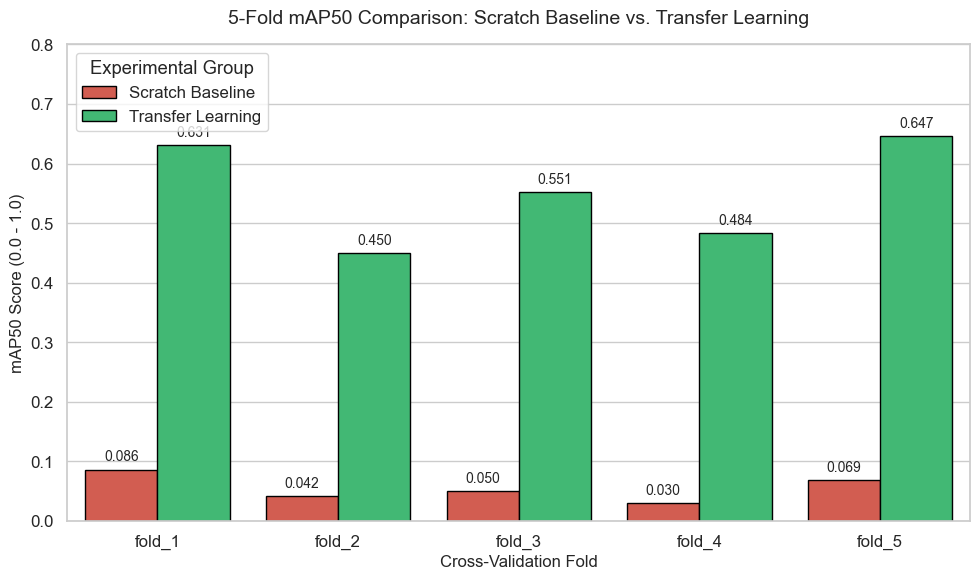

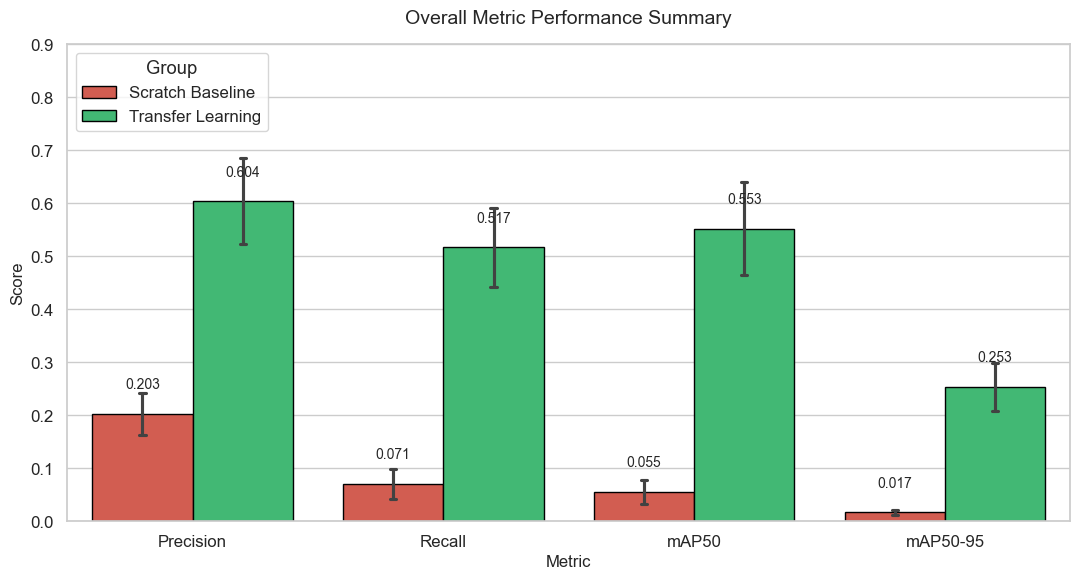

In [20]:
print("Generating Visual Assets")

# Generate plots
results_dir = '/content/drive/MyDrive/MSc Project/results'
charts_dir = '/content/drive/MyDrive/MSc Project/charts'
os.makedirs(charts_dir, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.1)
palette = ['#e74c3c', '#2ecc71'] # Red for scratch, green for transfer learning

# Load metric data
df_scratch = pd.read_csv(os.path.join(results_dir, 'results_scratch_baseline.csv'))
df_transfer = pd.read_csv(os.path.join(results_dir, 'results_transfer_learning.csv'))

df_scratch['Group'] = 'Scratch Baseline'
df_transfer['Group'] = 'Transfer Learning'
df_all = pd.concat([df_scratch, df_transfer], ignore_index=True)


# Figure 1: Per-Fold mAP50 Comparison Bar Chart

plt.figure(figsize=(10, 6))
ax1 = sns.barplot(data=df_all, x='Fold', y='mAP50', hue='Group', palette=palette, edgecolor='black', linewidth=1)

plt.title('5-Fold mAP50 Comparison: Scratch Baseline vs. Transfer Learning', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('mAP50 Score (0.0 - 1.0)', fontsize=12, fontweight='bold')
plt.xlabel('Cross-Validation Fold', fontsize=12, fontweight='bold')
plt.ylim(0, 0.8)

# Add exact score values above each bar
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.3f}', (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')

plt.legend(title='Experimental Group', frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
fig1_path = os.path.join(charts_dir, 'map50_fold_comparison.png')
plt.savefig(fig1_path, dpi=300)
plt.show()

print("\n")


# FIGURE 2: Overall Metric Performance (Mean +- Standard Deviation)

df_melt = df_all.melt(id_vars=['Fold', 'Group'], value_vars=['Precision', 'Recall', 'mAP50', 'mAP50-95'], var_name='Metric', value_name='Score')

plt.figure(figsize=(11, 6))
ax2 = sns.barplot(data=df_melt, x='Metric', y='Score', hue='Group', palette=palette, edgecolor='black', linewidth=1, errorbar='sd', capsize=0.05)

# Add mean values above bars
for p in ax2.patches:
    height = p.get_height()

    if not np.isnan(height) and height > 0:
        ax2.annotate(f'{height:.3f}', (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 16), textcoords='offset points')

plt.title('Overall Metric Performance Summary', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Score', fontsize=12, fontweight='bold')
plt.xlabel('Metric', fontsize=12, fontweight='bold')
plt.ylim(0, 0.9)
plt.legend(title='Group', frameon=True, facecolor='white', loc='upper left')

plt.tight_layout()
fig2_path = os.path.join(charts_dir, 'overall_metrics_summary.png')
plt.savefig(fig2_path, dpi=300)
plt.show()

Qualitative Inference Grid

Generating Visual Prediction Maps

Processing Image 1/3


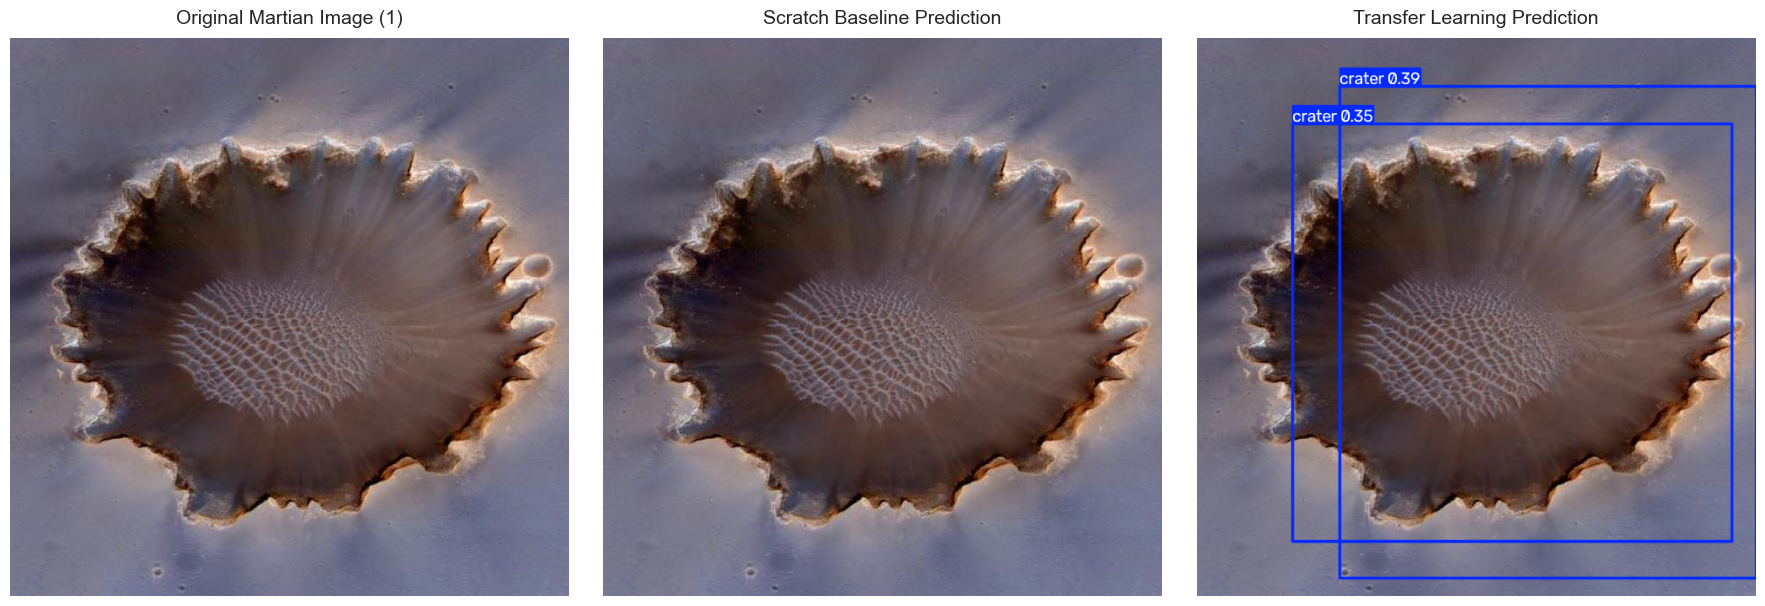


Processing Image 2/3


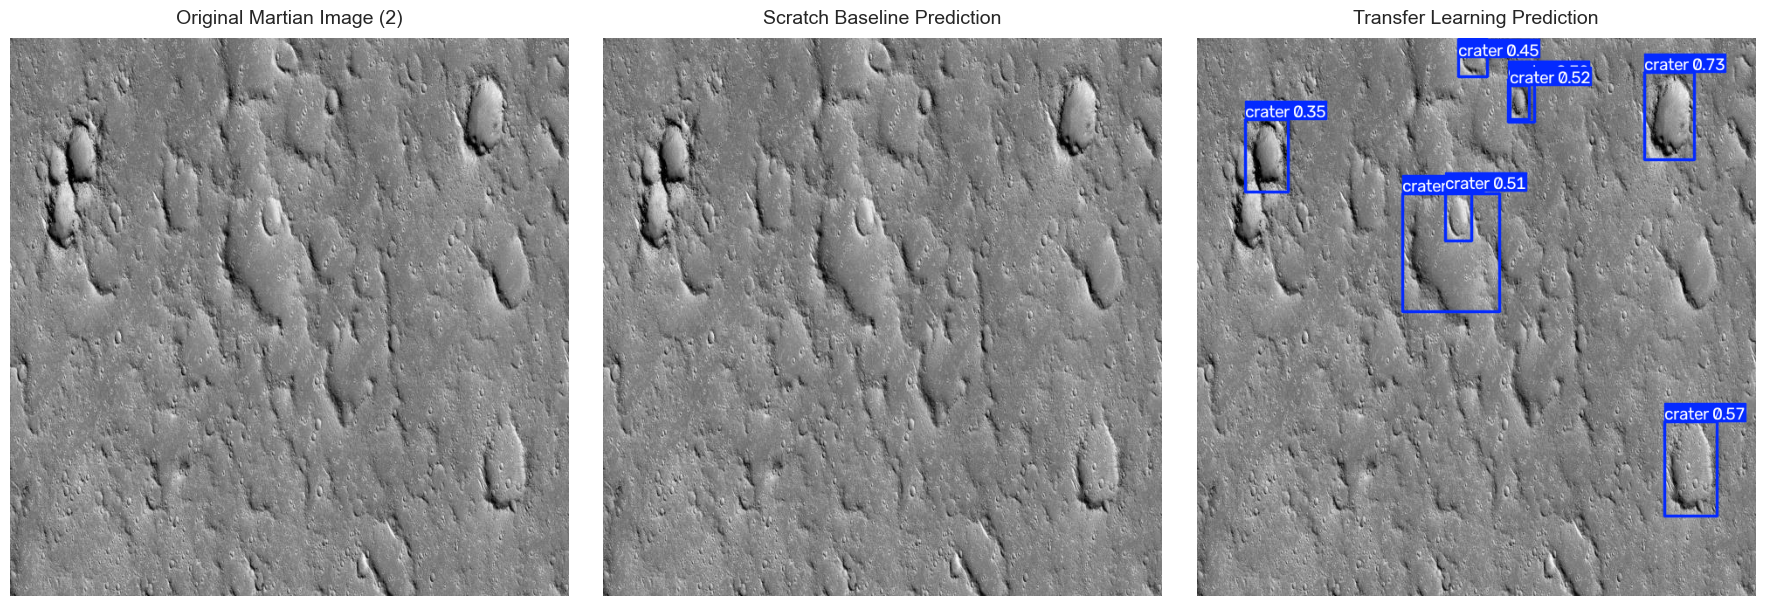


Processing Image 3/3


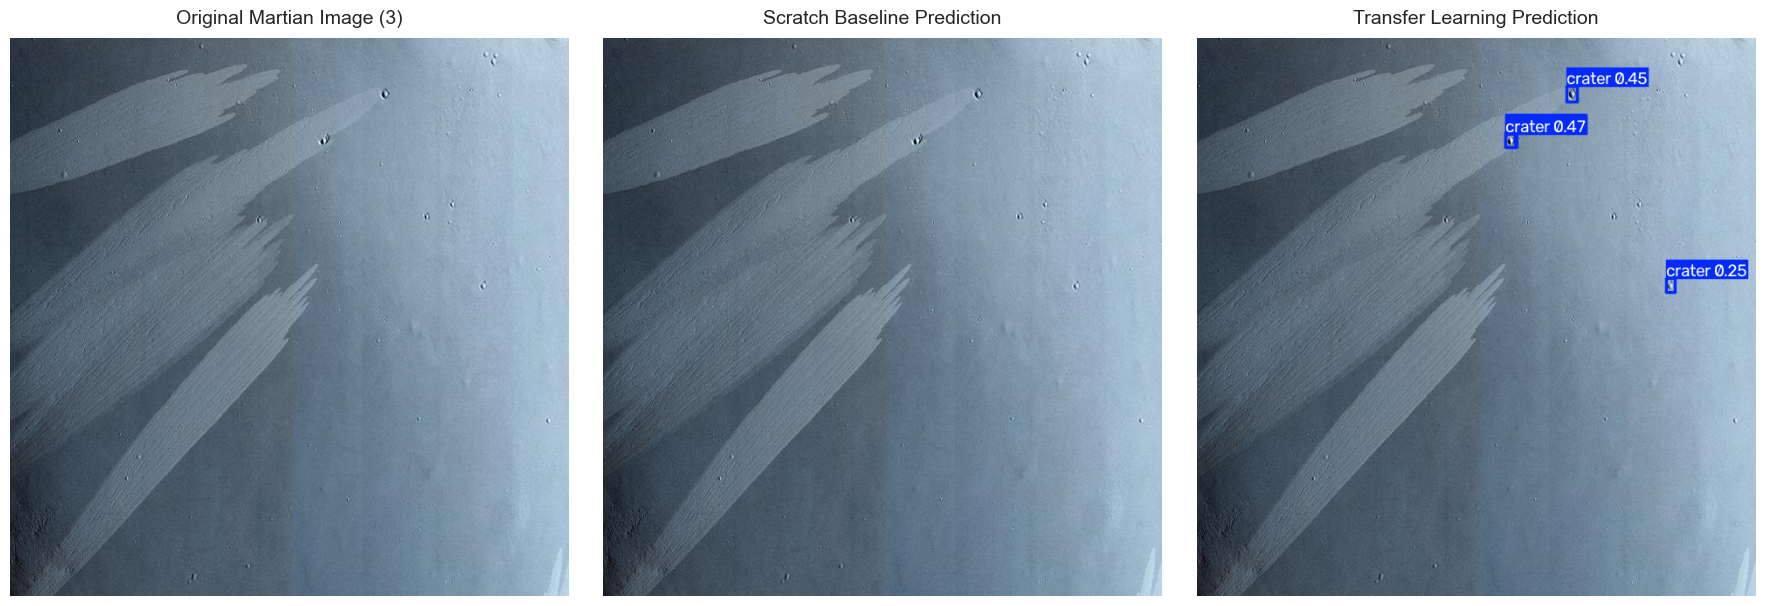

In [22]:
print("Generating Visual Prediction Maps")

# Set up paths to the best fold 1 weights for comparison
scratch_model_path = '/content/runs/scratch_baseline/fold_1/weights/best.pt'
transfer_model_path = '/content/runs/transfer_learning/fold_1/weights/best.pt'
charts_dir = '/content/drive/MyDrive/MSc Project/charts'
val_images_dir = '/content/datasets/pure_martian/images'

# Load both models into memory
scratch_model = YOLO(scratch_model_path)
transfer_model = YOLO(transfer_model_path)

# Select validation images
val_images = [f for f in os.listdir(val_images_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

if not val_images:
    print("Could not find validation images.")
else:
    # Select 3 random images
    num_samples = min(3, len(val_images))
    sample_img_names = random.sample(val_images, num_samples)

    for i, sample_img_name in enumerate(sample_img_names, start=1):
        sample_img_path = os.path.join(val_images_dir, sample_img_name)
        print(f"\nProcessing Image {i}/{num_samples}")

        # Run inference (conf=0.25 filters out extremely weak guesses)
        res_scratch = scratch_model.predict(sample_img_path, conf=0.25, verbose=False)
        res_transfer = transfer_model.predict(sample_img_path, conf=0.25, verbose=False)

        # Extract annotated images (YOLO outputs BGR so we convert to RGB for matplotlib)
        img_original = cv2.cvtColor(cv2.imread(sample_img_path), cv2.COLOR_BGR2RGB)
        img_scratch = res_scratch[0].plot()[..., ::-1]
        img_transfer = res_transfer[0].plot()[..., ::-1]

        # Plot side by side comparison grid
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        axes[0].imshow(img_original)
        axes[0].set_title(f'Original Martian Image ({i})', fontsize=14, fontweight='bold', pad=10)
        axes[0].axis('off')

        axes[1].imshow(img_scratch)
        axes[1].set_title('Scratch Baseline Prediction', fontsize=14, fontweight='bold', pad=10)
        axes[1].axis('off')

        axes[2].imshow(img_transfer)
        axes[2].set_title('Transfer Learning Prediction', fontsize=14, fontweight='bold', pad=10)
        axes[2].axis('off')

        plt.tight_layout()

        # Save the visual
        save_path = os.path.join(charts_dir, f'visual_inference_comparison_{i}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

##